# Corporate Announcement Tone and Stock Market Reaction
### Evidence from Indian Financial Institutions during the IL&FS Crisis

End-to-end pipeline: filter NSE corporate announcements -> extract PDF/ZIP text -> compute FinBERT sentiment (readability robustness measures) -> market-model event study (CAR) -> merge master dataset -> regression.


**Runtime note:** FinBERT (Section 9) downloads a ~400MB model on first run and is the slowest section, especially on CPU.

## Section 1: Configuration

In [68]:
import json
import re
import shutil
import zipfile
import logging
import unicodedata
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from tqdm.notebook import tqdm

# ============================================================
# Project Configuration
# ============================================================

ROOT_DIR = Path(r"C:\Users\sanka\OneDrive\Documents\AI & Trading")
RAW_DIR = ROOT_DIR / "data" / "raw"

DIRS = {
    "filtered": ROOT_DIR / "data" / "filtered",
    "extracted": ROOT_DIR / "data" / "extracted",
    "cleaned": ROOT_DIR / "data" / "cleaned",
    "features": ROOT_DIR / "data" / "features",
    "event_study": ROOT_DIR / "data" / "event_study",
    "results": ROOT_DIR / "data" / "results",
    "logs": ROOT_DIR / "logs",
}

for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# ============================================================
# Logging
# ============================================================

logging.basicConfig(
    filename=DIRS["logs"] / "event_study_pipeline.log",
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    force=True,
)

logger = logging.getLogger("event_study")

# ============================================================
# Companies
# ============================================================

COMPANIES = {
    "HDFC_Bank": "HDFCBANK",
    "ICICI_Bank": "ICICIBANK",
    "Axis_Bank": "AXISBANK",
    "SBI": "SBIN",
    "Kotak_Mahindra_Bank": "KOTAKBANK",
    "Bajaj_Finance": "BAJFINANCE",
    "Bajaj_Finserv": "BAJAJFINSV",
    "Shriram_Finance": "SHRIRAMFIN",
    "LIC_Housing_Finance": "LICHSGFIN",
    "PNB_Housing_Finance": "PNBHOUSING",
}

# ============================================================
# Study Period
# ============================================================

TEXT_START = pd.Timestamp("2018-01-01")
TEXT_END = pd.Timestamp("2019-03-31")

# Extra history required for the market-model estimation window
MARKET_START = pd.Timestamp("2017-01-01")
MARKET_END = pd.Timestamp("2019-03-31")

# ============================================================
# Market Data
# ============================================================

MARKET_DATA_DIR = RAW_DIR / "market_data"
NIFTY_FILE = MARKET_DATA_DIR / "NIFTY50.csv"

# ============================================================
# Event Study Parameters
# ============================================================

# Market-model estimation window
EST_WINDOW = (-120, -21)

# Event windows used in the analysis
EVENT_WINDOWS = {
    "CAR_m1_p1": (-1, 1),
    "CAR_0_p1": (0, 1),
    "CAR_m3_p3": (-3, 3),
}

# INCLUDE_KEYWORDS / EXCLUDE_KEYWORDS are defined later,
# immediately before the filtering logic.

# ============================================================
# Configuration Check
# ============================================================

print("Configuration loaded.")
print(f"Companies: {len(COMPANIES)}")
print(f"Market data directory present: {MARKET_DATA_DIR.exists()}")

Configuration loaded.
Companies: 10
Market data directory present: True


## Section 2: Load Metadata

In [2]:
def safe_read_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


all_metadata = []
for company in COMPANIES:
    meta_path = RAW_DIR / "announcements" / company / "metadata.csv"
    df = safe_read_csv(meta_path)
    if df.empty:
        logger.warning(f"{company}: no metadata found at {meta_path}")
        continue
    df["company"] = company
    all_metadata.append(df)

metadata = pd.concat(all_metadata, ignore_index=True) if all_metadata else pd.DataFrame()
metadata["broadcast_date"] = pd.to_datetime(metadata["broadcast_date"], errors="coerce")

metadata = metadata[
    (metadata["broadcast_date"] >= TEXT_START) &
    (metadata["broadcast_date"] <= TEXT_END) &
    (metadata["download_status"].isin(["downloaded", "skipped_exists"]))
].copy()

print(f"Loaded {len(metadata)} announcements with valid PDFs in the text period.")
logger.info(f"Loaded {len(metadata)} announcements after date/status filtering.")

Loaded 2089 announcements with valid PDFs in the text period.


## Section 3: Filter Announcements

In [ ]:
# NSE's 'subject' field is a short, standardized category label, confirmed
# via inspection. Exact-match against the observed vocabulary. 'description'
# is boilerplate for nearly every row and is NOT used for filtering.

KEEP_SUBJECTS = {
    "Financial Result Updates", "Financial Results Updates",
    "Reply to Clarification Sought", "Reply to Clarification- Financial results",
    "Option to submit Standalone/Consolidated Financial Results",
    "Credit Rating", "Investor Presentation", "Acquisition",
    "Raising of Funds", "Issue of Securities", "Press Release",
    "News Clarification", "News Verification",
    "Statement of deviation(s) or variation(s) under Reg. 32",
    "Preferential issue", "Strikes/Lockouts/Disturbances",
    "Outcome of Board Meeting", "Disc. under Reg.30 of SEBI (SAST) Reg.2011",
    "Allotment of Securities", "Qualified Institutional Placement",
    "Diversification/Disinvestment", "Offer for sale",
    "Offer For Sale-Stock Exchange Mechanism", "Change in Auditors",
}

REMOVE_SUBJECTS = {
    "Record Date", "Trading Window", "Book Closure", "AGM/Book Closure",
    "Shareholders meeting", "Committee Meeting Updates", "Appointment",
    "Resignation", "Reappointment", "Cessation", "Change in Director(s)",
    "ESOP/ESOS/ESPS", "Allotment of ESOP/ESPS",
    "Registrar & Share Transfer Agent Update", "Dividend", "Dividend Updates",
    "Meeting Updates", "Analysts/Institutional Investor Meet/Con. Call Updates",
    "Corrigendum", "Clarification", "Trading Plan under PIT", "Retirement",
    "Redemption", "Code of Conduct under SEBI(PIT) Reg., 2015",
    "Updates", "Others",
}


def classify_announcement(subject):
    """Returns (bucket, reason). bucket in {'keep','remove','unclassified'}."""
    if pd.isna(subject) or not str(subject).strip():
        return "remove", "no_subject_text"
    s = str(subject).strip()

    if s in KEEP_SUBJECTS:
        return "keep", f"kept_subject:{s}"
    if s in REMOVE_SUBJECTS:
        return "remove", f"removed_subject:{s}"
    return "unclassified", f"UNSEEN_SUBJECT:{s}"


classification = metadata["subject"].apply(classify_announcement)
metadata["_bucket"] = classification.apply(lambda t: t[0])
metadata["_reason"] = classification.apply(lambda t: t[1])

filtered_metadata = metadata[metadata["_bucket"] == "keep"].drop(columns=["_bucket"]).copy()
discarded_metadata = metadata[metadata["_bucket"] == "remove"].drop(columns=["_bucket"]).copy()
unclassified_metadata = metadata[metadata["_bucket"] == "unclassified"].drop(columns=["_bucket"]).copy()

filtered_metadata.to_csv(DIRS["filtered"] / "filtered_metadata.csv", index=False)
discarded_metadata.to_csv(DIRS["filtered"] / "discarded_metadata.csv", index=False)
if not unclassified_metadata.empty:
    unclassified_metadata.to_csv(DIRS["filtered"] / "unclassified_metadata.csv", index=False)

print(f"Kept: {len(filtered_metadata)} | Removed: {len(discarded_metadata)} | "
      f"Unclassified (unexpected -- should be 0 now): {len(unclassified_metadata)} "
      f"-- out of {len(metadata)} total ({100*len(filtered_metadata)/len(metadata):.1f}% kept)\n")
print("Kept by subject:")
print(filtered_metadata["subject"].value_counts())
if not unclassified_metadata.empty:
    print("\nWARNING -- still-unclassified subjects (should not happen, investigate):")
    print(unclassified_metadata["subject"].value_counts())
logger.info(f"Filtering (exact-match, finalized): kept {len(filtered_metadata)} of {len(metadata)}")

Kept: 312 | Removed: 1777 | Unclassified (unexpected -- should be 0 now): 0 -- out of 2089 total (14.9% kept)

Kept by subject:
subject
Financial Result Updates                                      50
Outcome of Board Meeting                                      50
News Clarification                                            41
Investor Presentation                                         34
Raising of Funds                                              24
Issue of Securities                                           23
Press Release                                                 23
Disc. under Reg.30 of SEBI (SAST) Reg.2011                    12
News Verification                                             10
Acquisition                                                    9
Reply to Clarification Sought                                  7
Allotment of Securities                                        7
Credit Rating                                                  4
Option to submit St

## Section 4: Copy Relevant Announcement Files

In [9]:
def copy_filtered_files(df: pd.DataFrame) -> list:
    new_paths = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Copying files"):
        src = row.get("local_pdf_path", "")
        if pd.isna(src) or not str(src).strip() or not Path(src).exists():
            new_paths.append("")
            continue
        src_path = Path(src)
        dest_dir = DIRS["filtered"] / row["company"]
        dest_dir.mkdir(parents=True, exist_ok=True)
        dest_path = dest_dir / src_path.name
        if not dest_path.exists():
            try:
                shutil.copy2(src_path, dest_path)
            except Exception as e:
                logger.error(f"Failed to copy {src_path}: {e}")
                new_paths.append("")
                continue
        new_paths.append(str(dest_path))
    return new_paths


filtered_metadata["filtered_file_path"] = copy_filtered_files(filtered_metadata)
n_missing = (filtered_metadata["filtered_file_path"] == "").sum()
print(f"Copied files. {n_missing} announcements had no accessible local file.")
filtered_metadata.to_csv(
    r"C:\Users\sanka\OneDrive\Documents\AI & Trading\data\results\filtered_metadata.csv",
    index=False
)

Copying files:   0%|          | 0/312 [00:00<?, ?it/s]

Copied files. 0 announcements had no accessible local file.


## Section 5: ZIP Extraction

In [10]:
IGNORE_EXTENSIONS = {".xlsx", ".xls", ".csv", ".xml", ".xbrl", ".png", ".jpg", ".jpeg", ".gif"}

def resolve_pdf_paths(file_path: str, company: str) -> list:
    if not file_path:
        return []
    path = Path(file_path)

    if path.suffix.lower() == ".pdf":
        return [str(path)]

    if path.suffix.lower() == ".zip":
        extract_dir = DIRS["extracted"] / company / path.stem
        extract_dir.mkdir(parents=True, exist_ok=True)
        try:
            with zipfile.ZipFile(path, "r") as z:
                z.extractall(extract_dir)
        except zipfile.BadZipFile:
            logger.error(f"Corrupt ZIP, skipping: {path}")
            return []
        pdfs = [str(p) for p in extract_dir.rglob("*.pdf")]
        return pdfs

    logger.warning(f"Unrecognized file type, skipping: {path}")
    return []


resolved_rows = []
for _, row in tqdm(filtered_metadata.iterrows(), total=len(filtered_metadata), desc="Resolving PDFs"):
    pdf_paths = resolve_pdf_paths(row["filtered_file_path"], row["company"])
    for pdf_path in pdf_paths:
        new_row = row.to_dict()
        new_row["pdf_path"] = pdf_path
        resolved_rows.append(new_row)

resolved_df = pd.DataFrame(resolved_rows)
print(f"Resolved {len(filtered_metadata)} announcements into {len(resolved_df)} PDF documents.")
logger.info(f"Resolved into {len(resolved_df)} individual PDFs.")

Resolving PDFs:   0%|          | 0/312 [00:00<?, ?it/s]

Resolved 312 announcements into 313 PDF documents.


## Section 6: PDF Text Extraction

In [11]:
import fitz  # PyMuPDF
import pdfplumber

def extract_text_pymupdf(pdf_path: str) -> str:
    doc = fitz.open(pdf_path)
    text = "\n".join(page.get_text() for page in doc)
    doc.close()
    return text


def extract_text_pdfplumber(pdf_path: str) -> str:
    with pdfplumber.open(pdf_path) as pdf:
        return "\n".join(page.extract_text() or "" for page in pdf.pages)


def extract_text(pdf_path: str) -> str:
    try:
        text = extract_text_pymupdf(pdf_path)
        if len(text.strip()) > 20:
            return text
    except Exception as e:
        logger.warning(f"PyMuPDF failed on {pdf_path}: {e}")

    try:
        text = extract_text_pdfplumber(pdf_path)
        return text
    except Exception as e:
        logger.error(f"pdfplumber also failed on {pdf_path}: {e}")
        return ""


raw_texts = []
for pdf_path in tqdm(resolved_df["pdf_path"], desc="Extracting PDF text"):
    raw_texts.append(extract_text(pdf_path))

resolved_df["raw_text"] = raw_texts
n_empty = (resolved_df["raw_text"].str.strip() == "").sum()
print(f"Extracted text from {len(resolved_df)} PDFs. {n_empty} yielded no text "
      f"(likely scanned/image-only, logged and will be dropped downstream).")

Extracting PDF text:   0%|          | 0/313 [00:00<?, ?it/s]

Extracted text from 313 PDFs. 85 yielded no text (likely scanned/image-only, logged and will be dropped downstream).


## Section 7: Text Cleaning

In [12]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
PAGE_NUM_RE = re.compile(r"(?i)page\s*\d+\s*(of\s*\d+)?")
MULTI_WS_RE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    if not text:
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    text = PAGE_NUM_RE.sub(" ", text)

    lines = [l.strip() for l in text.split("\n")]
    line_counts = pd.Series(lines).value_counts()
    boilerplate = set(line_counts[(line_counts > 2) & (line_counts.index.str.len() < 80)].index)
    boilerplate.discard("")
    lines = [l for l in lines if l not in boilerplate]

    text = " ".join(lines)
    text = MULTI_WS_RE.sub(" ", text).strip()
    return text


resolved_df["clean_text"] = resolved_df["raw_text"].apply(clean_text)
resolved_df = resolved_df[resolved_df["clean_text"].str.len() > 20].reset_index(drop=True)
print(f"{len(resolved_df)} documents remain after cleaning and dropping empty extractions.")

226 documents remain after cleaning and dropping empty extractions.


## Section 8: Tokenisation

In [13]:
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.tokenize import sent_tokenize, word_tokenize

def tokenise_stats(text: str) -> dict:
    sentences = sent_tokenize(text) if text else []
    words = word_tokenize(text) if text else []
    words_alpha = [w for w in words if w.isalpha()]
    avg_word_len = np.mean([len(w) for w in words_alpha]) if words_alpha else 0.0
    return {
        "word_count": len(words_alpha),
        "sentence_count": len(sentences),
        "average_word_length": avg_word_len,
    }


tok_stats = resolved_df["clean_text"].apply(tokenise_stats).apply(pd.Series)
resolved_df = pd.concat([resolved_df, tok_stats], axis=1)
resolved_df.to_csv(DIRS["cleaned"] / "cleaned_documents.csv", index=False)
print(resolved_df[["word_count", "sentence_count", "average_word_length"]].describe())

         word_count  sentence_count  average_word_length
count    226.000000      226.000000           226.000000
mean    2151.146018       78.654867             5.267174
std     4913.412596      172.096163             0.236788
min      106.000000        4.000000             4.454477
25%      272.500000       15.000000             5.146739
50%      676.500000       31.500000             5.296906
75%     3194.250000      100.750000             5.367623
max    69183.000000     2403.000000             6.076531


## Section 9: Textual Measure -- FinBERT

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

FINBERT_MODEL = "ProsusAI/finbert"
_finbert_tokenizer = AutoTokenizer.from_pretrained(FINBERT_MODEL)
_finbert_model = AutoModelForSequenceClassification.from_pretrained(FINBERT_MODEL)
_finbert_model.eval()
_device = "cuda" if torch.cuda.is_available() else "cpu"
_finbert_model.to(_device)
print(f"FinBERT loaded on {_device}.")

LABELS = ["positive", "negative", "neutral"]

def finbert_score(text: str, max_chunk_words: int = 400) -> dict:
    if not text or not text.strip():
        return {"finbert_positive": np.nan, "finbert_negative": np.nan,
                "finbert_neutral": np.nan, "finbert_score": np.nan,
                "finbert_class": None}

    words = text.split()
    chunks = [" ".join(words[i:i + max_chunk_words])
              for i in range(0, len(words), max_chunk_words)]

    weighted_probs = np.zeros(3)
    total_weight = 0
    for chunk in chunks:
        inputs = _finbert_tokenizer(chunk, return_tensors="pt", truncation=True,
                                     max_length=512).to(_device)
        with torch.no_grad():
            logits = _finbert_model(**inputs).logits
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
        weight = len(chunk.split())
        weighted_probs += probs * weight
        total_weight += weight

    if total_weight == 0:
        return {"finbert_positive": np.nan, "finbert_negative": np.nan,
                "finbert_neutral": np.nan, "finbert_score": np.nan,
                "finbert_class": None}

    avg_probs = weighted_probs / total_weight
    pos, neg, neu = avg_probs[0], avg_probs[1], avg_probs[2]
    return {
        "finbert_positive": pos, "finbert_negative": neg, "finbert_neutral": neu,
        "finbert_score": pos - neg,
        "finbert_class": LABELS[int(np.argmax(avg_probs))],
    }


finbert_results = []
for text in tqdm(resolved_df["clean_text"], desc="Scoring FinBERT sentiment"):
    finbert_results.append(finbert_score(text))

resolved_df = pd.concat([resolved_df, pd.DataFrame(finbert_results)], axis=1)
print(resolved_df["finbert_score"].describe())

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT loaded on cpu.


Scoring FinBERT sentiment:   0%|          | 0/226 [00:00<?, ?it/s]

count    226.000000
mean       0.072550
std        0.137749
min       -0.129364
25%       -0.005070
50%        0.014446
75%        0.117138
max        0.796321
Name: finbert_score, dtype: float64


## Section 10: Robustness Measures -- LM Dictionary and Readability

In [67]:
import textstat


def readability_scores(text: str) -> dict:
    if not text or len(text.split()) < 10:
        return {
            "flesch_reading_ease": np.nan,
            "flesch_kincaid_grade": np.nan,
        }

    try:
        return {
            "flesch_reading_ease": textstat.flesch_reading_ease(text),
            "flesch_kincaid_grade": textstat.flesch_kincaid_grade(text),
        }
    except Exception:
        return {
            "flesch_reading_ease": np.nan,
            "flesch_kincaid_grade": np.nan,
        }


# Compute readability
read_df = resolved_df["clean_text"].apply(readability_scores).apply(pd.Series)

resolved_df = pd.concat([resolved_df, read_df], axis=1)

# Log word count
resolved_df["log_word_count"] = np.log1p(resolved_df["word_count"])

print("Readability measures computed.")

Readability measures computed.


## Section 11: Load Market Data

In [56]:
def load_price_series(path: Path) -> pd.DataFrame:
    df = safe_read_csv(path)
    if df.empty:
        return df
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    df["return"] = df["close"].pct_change()
    return df[["date", "close", "return"]]


nifty_prices = load_price_series(NIFTY_FILE)
if nifty_prices.empty:
    print(f"WARNING: NIFTY50 market data not found at {NIFTY_FILE}. "
          f"Confirm the file exists and matches the expected 'date'/'close' schema "
          f"before proceeding -- the event study cannot run without it.")

company_prices = {}
for company in COMPANIES.keys():
    p = MARKET_DATA_DIR / f"{company}.csv"

    df = load_price_series(p)

    if df.empty:
        print(f"WARNING: no market data found for {company} at {p}")

    company_prices[company] = df
    df = load_price_series(p)
    if df.empty:
        print(f"WARNING: no market data found for {company} at {p}")
    company_prices[company] = df

print(f"Loaded market data for {sum(not v.empty for v in company_prices.values())} "
      f"of {len(COMPANIES)} companies.")

Loaded market data for 10 of 10 companies.


## Section 12: Event Study (Market Model, CAR)

In [57]:
def compute_car(event_date: pd.Timestamp, stock_df: pd.DataFrame,
                market_df: pd.DataFrame) -> dict:

    # Convert timestamp (e.g. 2018-10-20 18:52:00)
    # to date only (2018-10-20 00:00:00)
    event_date = pd.Timestamp(event_date).normalize()

    merged = pd.merge(stock_df, market_df, on="date",
                      suffixes=("_stock", "_market"))
    merged = merged.sort_values("date").reset_index(drop=True)

    idx_candidates = merged.index[merged["date"] >= event_date]
    if len(idx_candidates) == 0:
        return {}
    event_idx = idx_candidates[0]

    est_start = event_idx + EST_WINDOW[0]
    est_end = event_idx + EST_WINDOW[1]
    if est_start < 0:
        return {}

    est_data = merged.iloc[est_start:est_end + 1].dropna(
        subset=["return_stock", "return_market"])
    if len(est_data) < 90:
        return {}

    X = sm.add_constant(est_data["return_market"])
    y = est_data["return_stock"]
    model = sm.OLS(y, X).fit()
    alpha, beta = model.params.get("const", 0.0), model.params.get("return_market", 0.0)

    result = {}
    for label, (w_start, w_end) in EVENT_WINDOWS.items():
        w_start_idx = event_idx + w_start
        w_end_idx = event_idx + w_end
        if w_start_idx < 0 or w_end_idx >= len(merged):
            result[label] = np.nan
            continue
        window = merged.iloc[w_start_idx:w_end_idx + 1]
        expected = alpha + beta * window["return_market"]
        abnormal = window["return_stock"] - expected
        result[label] = abnormal.sum()

    return result


car_results = []
for _, row in tqdm(resolved_df.iterrows(), total=len(resolved_df), desc="Computing CAR"):
    stock_df = company_prices.get(row["company"], pd.DataFrame())
    if stock_df.empty or nifty_prices.empty:
        car_results.append({})
        continue
    car_results.append(
    compute_car(
        row["announcement_date"],
        stock_df,
        nifty_prices
    )
)

car_df = pd.DataFrame(car_results)
for col in EVENT_WINDOWS:
    if col not in car_df.columns:
        car_df[col] = np.nan
# Remove old CAR columns if they already exist
resolved_df = resolved_df.loc[
    :,
    ~resolved_df.columns.str.startswith("car_")
]
resolved_df = pd.concat([resolved_df, car_df], axis=1)

print(f"CAR computed for {resolved_df['car_m1_p1'].notna().sum()} of "
      f"{len(resolved_df)} announcements (others lacked sufficient market data).")

Computing CAR: 100%|██████████| 226/226 [00:01<00:00, 207.74it/s]

CAR computed for 221 of 226 announcements (others lacked sufficient market data).


In [62]:
resolved_df.sort_values("flesch_reading_ease").head(5)[
    [
        "company",
        "announcement_date",
        "subject",
        "flesch_reading_ease",
        "word_count",
        "filtered_file_path"
    ]
]

,company,announcement_date,subject,flesch_reading_ease,word_count,filtered_file_path
2,HDFC_Bank,14-Nov-2018 18:56:00,Statement of deviation(s) or variation(s) unde...,0.844000,183.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
210,PNB_Housing_Finance,19-May-2018 14:48:00,Investor Presentation,8.967308,2938.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
65,Axis_Bank,29-Jan-2019 16:23:00,Press Release,11.500349,689.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
80,SBI,07-Jun-2018 18:24:00,Press Release,16.251124,999.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
151,Bajaj_Finserv,29-Mar-2019 15:29:00,Investor Presentation,21.705228,4017.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...


In [63]:
resolved_df.sort_values("word_count", ascending=False).head(10)[
    [
        "company",
        "subject",
        "word_count",
        "filtered_file_path"
    ]
]

,company,subject,word_count,filtered_file_path
94,Kotak_Mahindra_Bank,Issue of Securities,69183.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
91,Kotak_Mahindra_Bank,Outcome of Board Meeting,7613.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
92,Kotak_Mahindra_Bank,Financial Result Updates,7613.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
66,Axis_Bank,Financial Result Updates,7329.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
53,Axis_Bank,Financial Result Updates,7207.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
54,Axis_Bank,Outcome of Board Meeting,7207.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
49,Axis_Bank,Financial Result Updates,7074.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
57,Axis_Bank,Outcome of Board Meeting,7021.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
58,Axis_Bank,Financial Result Updates,7021.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...
40,ICICI_Bank,Financial Result Updates,6809.0,C:\Users\sanka\OneDrive\Documents\AI & Trading...


In [64]:
master_dataset[
    [
        "finbert_score",
        "CAR_m1_p1",
        "CAR_0_p1",
        "CAR_m3_p3"
    ]
].corr()

,finbert_score,CAR_m1_p1,CAR_0_p1,CAR_m3_p3
finbert_score,1.000000,-0.000140,0.043786,-0.057354
CAR_m1_p1,-0.000140,1.000000,0.891521,0.823394
CAR_0_p1,0.043786,0.891521,1.000000,0.688970
CAR_m3_p3,-0.057354,0.823394,0.688970,1.000000


## Section 13: Master Dataset

In [58]:
master_cols = [
    "company", "broadcast_date", "subject", "finbert_score", "finbert_positive",
    "finbert_negative", "finbert_neutral", "finbert_class",
    "lm_positive", "lm_negative", "lm_uncertainty", "lm_litigious", "lm_constraining",
    "flesch_reading_ease", "flesch_kincaid_grade", "word_count", "log_word_count",
    "car_m1_p1", "car_0_p1", "car_m3_p3",
]
master_dataset = resolved_df[master_cols].rename(columns={
    "broadcast_date": "announcement_date",
    "car_m1_p1": "CAR_m1_p1", "car_0_p1": "CAR_0_p1", "car_m3_p3": "CAR_m3_p3",
})
master_dataset["year"] = pd.to_datetime(master_dataset["announcement_date"]).dt.year
master_dataset = master_dataset.dropna(subset=["finbert_score", "CAR_m1_p1"])

master_dataset.to_csv(DIRS["features"] / "master_dataset.csv", index=False)
print(f"Master dataset: {len(master_dataset)} announcements ready for regression.")
master_dataset.head()

Master dataset: 221 announcements ready for regression.


,company,announcement_date,subject,finbert_score,finbert_positive,finbert_negative,finbert_neutral,finbert_class,lm_positive,lm_negative,...,lm_litigious,lm_constraining,flesch_reading_ease,flesch_kincaid_grade,word_count,log_word_count,CAR_m1_p1,CAR_0_p1,CAR_m3_p3,year
0,HDFC_Bank,2018-12-28 17:32:00,Allotment of Securities,0.024934,0.040962,0.016027,0.943011,neutral,NaN,NaN,...,NaN,NaN,55.196694,9.411129,129.0,4.867534,-0.007395,0.003468,-0.006661,2018
1,HDFC_Bank,2018-11-20 17:51:00,Acquisition,0.038147,0.054901,0.016753,0.928346,neutral,NaN,NaN,...,NaN,NaN,35.093415,13.632885,562.0,6.333280,0.012257,0.012849,0.042204,2018
2,HDFC_Bank,2018-11-14 18:56:00,Statement of deviation(s) or variation(s) unde...,0.020600,0.038650,0.018050,0.943300,neutral,NaN,NaN,...,NaN,NaN,0.844000,25.563000,183.0,5.214936,0.018665,0.022144,0.017360,2018
3,HDFC_Bank,2018-10-26 18:50:00,Acquisition,-0.002082,0.022006,0.024088,0.953906,neutral,NaN,NaN,...,NaN,NaN,35.906072,12.778949,513.0,6.242223,-0.034701,-0.030529,-0.052920,2018
4,HDFC_Bank,2018-10-20 15:47:25,Financial Result Updates,0.145115,0.182977,0.037862,0.779162,neutral,NaN,NaN,...,NaN,NaN,45.346052,11.863917,3400.0,8.131825,0.025736,0.019363,0.006441,2018


## Section 14: Regression

In [65]:
event_windows = [
    "CAR_m1_p1",
    "CAR_0_p1",
    "CAR_m3_p3"
]

for dep_var in event_windows:

    print("=" * 80)
    print(f"Regression using {dep_var}")
    print("=" * 80)

    formula = (
        f"{dep_var} ~ finbert_score + "
        "log_word_count + "
        "flesch_reading_ease + "
        "C(company) + "
        "C(year)"
    )

    model = smf.ols(
        formula,
        data=master_dataset
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": master_dataset["company"]}
    )

    print(model.summary())

Regression using CAR_m1_p1
                            OLS Regression Results                            
Dep. Variable:              CAR_m1_p1   R-squared:                       0.187
Model:                            OLS   Adj. R-squared:                  0.140
Method:                 Least Squares   F-statistic:                     5.234
Date:                Fri, 07 Aug 2026   Prob (F-statistic):             0.0228
Time:                        17:10:28   Log-Likelihood:                 385.72
No. Observations:                 221   AIC:                            -745.4
Df Residuals:                     208   BIC:                            -701.3
Df Model:                          12                                         
Covariance Type:              cluster                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------

c:\Users\sanka\anaconda3\envs\ml_arb\lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 12, but rank is 4
  warnings.warn('covariance of constraints does not have full '
c:\Users\sanka\anaconda3\envs\ml_arb\lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 12, but rank is 4
  warnings.warn('covariance of constraints does not have full '
c:\Users\sanka\anaconda3\envs\ml_arb\lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 12, but rank is 4
  warnings.warn('covariance of constraints does not have full '


## Section 15: Robustness

In [69]:
# ============================================================
# Regression Models
# ============================================================

# Model 1: FinBERT sentiment only
model_1 = smf.ols(
    "CAR_m1_p1 ~ finbert_score + C(company) + C(year)",
    data=master_dataset
).fit(
    cov_type="cluster",
    cov_kwds={"groups": master_dataset["company"]}
)

# Model 2: FinBERT + control variables
model_2 = smf.ols(
    "CAR_m1_p1 ~ finbert_score + log_word_count + "
    "flesch_reading_ease + C(company) + C(year)",
    data=master_dataset
).fit(
    cov_type="cluster",
    cov_kwds={"groups": master_dataset["company"]}
)

print(
    "Regression models estimated:\n"
    "• Model 1: FinBERT sentiment only\n"
    "• Model 2: FinBERT sentiment + readability + word count controls"
)

Regression models estimated:
• Model 1: FinBERT sentiment only
• Model 2: FinBERT sentiment + readability + word count controls


In [70]:
# ============================================================
# Robustness Checks
# ============================================================

robustness_results = []

for car in ["CAR_m1_p1", "CAR_0_p1", "CAR_m3_p3"]:

    formula = (
        f"{car} ~ finbert_score + "
        "log_word_count + "
        "flesch_reading_ease + "
        "C(company) + C(year)"
    )

    model = smf.ols(formula, data=master_dataset).fit(
        cov_type="cluster",
        cov_kwds={"groups": master_dataset["company"]}
    )

    robustness_results.append({
        "CAR Window": car,
        "FinBERT Coef": model.params["finbert_score"],
        "FinBERT p-value": model.pvalues["finbert_score"],
        "R²": model.rsquared,
        "Adj. R²": model.rsquared_adj,
        "Observations": int(model.nobs)
    })

robustness_table = pd.DataFrame(robustness_results)

display(robustness_table)

print(
    "Robustness analysis completed using three pre-specified event windows:\n"
    "• CAR(-1,+1)\n"
    "• CAR(0,+1)\n"
    "• CAR(-3,+3)"
)

,CAR Window,FinBERT Coef,FinBERT p-value,R²,Adj. R²,Observations
0,CAR_m1_p1,-0.036449,0.166553,0.186569,0.139640,221
1,CAR_0_p1,-0.023854,0.326647,0.226474,0.181848,221
2,CAR_m3_p3,-0.086416,0.040648,0.118144,0.067267,221


Robustness analysis completed using three pre-specified event windows:
• CAR(-1,+1)
• CAR(0,+1)
• CAR(-3,+3)


## Section 16: Outputs (Figures and Tables)

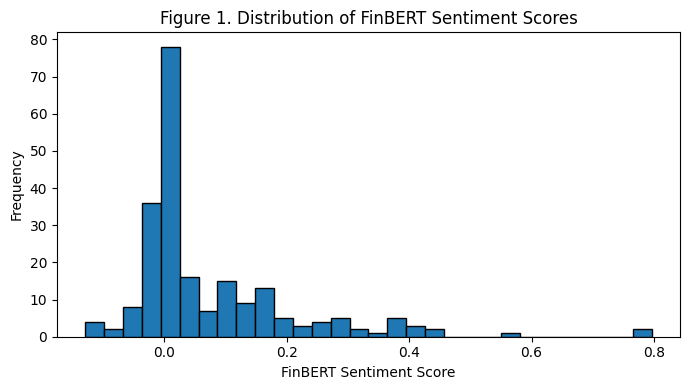

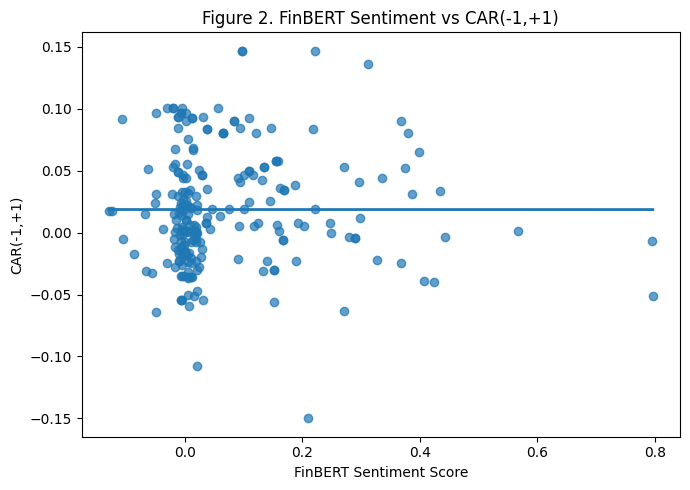

TABLE 1: SAMPLE SUMMARY


,company,n_announcements
0,Axis_Bank,21
1,Bajaj_Finance,35
2,Bajaj_Finserv,19
3,HDFC_Bank,19
4,ICICI_Bank,28
5,Kotak_Mahindra_Bank,12
6,PNB_Housing_Finance,34
7,SBI,17
8,Shriram_Finance,36



TABLE 2: DESCRIPTIVE STATISTICS


,finbert_score,CAR_m1_p1,CAR_0_p1,CAR_m3_p3,word_count,flesch_reading_ease
count,221.000000,221.000000,221.000000,221.000000,221.000000,221.000000
mean,0.072960,0.018645,0.017186,0.022548,1864.552036,43.771729
std,0.137620,0.046946,0.041472,0.070590,2029.995666,11.348538
min,-0.129364,-0.149969,-0.113790,-0.204991,106.000000,0.844000
25%,-0.005109,-0.013825,-0.008802,-0.021955,277.000000,36.026370
50%,0.015587,0.011692,0.012370,0.015853,679.000000,44.750793
75%,0.117439,0.048641,0.046471,0.063362,3120.000000,50.786667
max,0.796321,0.146887,0.131386,0.225640,7613.000000,74.681442



TABLE 3: ROBUSTNESS RESULTS


,CAR Window,FinBERT Coef,FinBERT p-value,R²,Adj. R²,Observations
0,CAR_m1_p1,-0.036449,0.166553,0.186569,0.139640,221
1,CAR_0_p1,-0.023854,0.326647,0.226474,0.181848,221
2,CAR_m3_p3,-0.086416,0.040648,0.118144,0.067267,221



Outputs saved to:
C:\Users\sanka\OneDrive\Documents\AI & Trading\data\results


In [71]:
# ============================================================
# Figures
# ============================================================

# Figure 1 ----------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    master_dataset["finbert_score"],
    bins=30,
    edgecolor="black"
)

ax.set_title("Figure 1. Distribution of FinBERT Sentiment Scores")
ax.set_xlabel("FinBERT Sentiment Score")
ax.set_ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    DIRS["results"] / "figure1_finbert_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Figure 2 ----------------------------------------------------

fig, ax = plt.subplots(figsize=(7,5))

x = master_dataset["finbert_score"]
y = master_dataset["CAR_m1_p1"]

ax.scatter(
    x,
    y,
    alpha=0.7
)

# Regression line
coef = np.polyfit(x, y, 1)
poly = np.poly1d(coef)

x_line = np.linspace(x.min(), x.max(), 100)

ax.plot(
    x_line,
    poly(x_line),
    linewidth=2
)

ax.set_title("Figure 2. FinBERT Sentiment vs CAR(-1,+1)")
ax.set_xlabel("FinBERT Sentiment Score")
ax.set_ylabel("CAR(-1,+1)")

plt.tight_layout()

plt.savefig(
    DIRS["results"] / "figure2_finbert_vs_car.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Table 1
# Sample Summary
# ============================================================

table1 = (
    master_dataset
    .groupby("company")
    .size()
    .rename("n_announcements")
    .reset_index()
)

table1.to_csv(
    DIRS["results"] / "table1_sample_summary.csv",
    index=False
)


# ============================================================
# Table 2
# Descriptive Statistics
# ============================================================

table2 = master_dataset[
    [
        "finbert_score",
        "CAR_m1_p1",
        "CAR_0_p1",
        "CAR_m3_p3",
        "word_count",
        "flesch_reading_ease",
    ]
].describe()

table2.to_csv(
    DIRS["results"] / "table2_descriptive_statistics.csv"
)


# ============================================================
# Table 3
# Main Regression
# ============================================================

with open(
    DIRS["results"] / "table3_main_regression.txt",
    "w"
) as f:

    f.write(primary_model.summary().as_text())


# ============================================================
# Table 4
# Robustness Results
# ============================================================

robustness_table.to_csv(
    DIRS["results"] / "table4_robustness_results.csv",
    index=False
)


# ============================================================
# Display Outputs
# ============================================================

print("="*70)
print("TABLE 1: SAMPLE SUMMARY")
print("="*70)
display(table1)

print()

print("="*70)
print("TABLE 2: DESCRIPTIVE STATISTICS")
print("="*70)
display(table2)

print()

print("="*70)
print("TABLE 3: ROBUSTNESS RESULTS")
print("="*70)
display(robustness_table)

print()

print("Outputs saved to:")
print(DIRS["results"])

## Section 17: Save Outputs

In [72]:
master_dataset.to_csv(DIRS["results"] / "master_dataset.csv", index=False)
resolved_df.to_csv(DIRS["event_study"] / "event_study_results.csv", index=False)
table2.to_csv(DIRS["results"] / "summary_statistics.csv")

reg_summary = pd.DataFrame({
    "model": ["Model 1 (FinBERT only)", "Model 2 (FinBERT + controls)",
              "Model 3 (LM Negative)"],
    "n_obs": [int(model_1.nobs), int(model_2.nobs),
              int(model_3.nobs) if model_3 is not None else np.nan],
    "r_squared": [model_1.rsquared, model_2.rsquared,
                  model_3.rsquared if model_3 is not None else np.nan],
})
reg_summary.to_csv(DIRS["results"] / "regression_results.csv", index=False)

print("All outputs saved to:", DIRS["results"])
print("\nPipeline complete.")

All outputs saved to: C:\Users\sanka\OneDrive\Documents\AI & Trading\data\results

Pipeline complete.
